<a href="https://colab.research.google.com/github/karkouri-zakaria/Systematic-review/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Load

In [ ]:
import pandas as pd

sheet_id = "1yVtEYCLz2WjjRdqe9_AmNn1oYVFKBJQXyHwp35CIMmA"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=xlsx"

try:
    # Load ONLY the "All" sheet
    df = pd.read_excel(url, sheet_name='All', engine='openpyxl')

    print("¡Excelente! 'All' sheet loaded successfully.\n")
    print(f"Shape: {df.shape}")

    # Show columns
    print(df.columns)

except Exception as e:
    print(f"Error al cargar los datos: {e}")

¡Excelente! 'All' sheet loaded successfully.

Shape: (42, 49)
Index(['Title', 'Year', 'doi', 'MD', 'Effect', 'Device', 'Device_category ',
       'Num', 'ST', 'Category_ST', 'Therapy', 'Adaptability', 'Categorization',
       'Psychotherapy & CBT', 'Lifestyle & Mindfulness', 'Human Support',
       'Conversational AI', 'XR & Gamification', 'JITAI, EMA & Sensing',
       'Classification', 'Mechanism', 'Evaluation', 'Type', 'WPC: MOB',
       'WPC: SEM', 'WPC: ABS', 'WPC: AMB', 'WPC: VIR', 'WCC: APP', 'WCC: TSK',
       'WCC: MAC', 'WCC: MIC', 'WSC: COM', 'WSC: PEER', 'WSC: CLIN',
       'WSC: PROX', 'H: GPS', 'H: WIF', 'H: MOT', 'H: MIC', 'H: BLS', 'H: LIS',
       'H: VAR', 'H: APP', 'H: EOS', 'H: OUT', 'H: DSA', 'H: REP', 'H: DIR'],
      dtype='object')


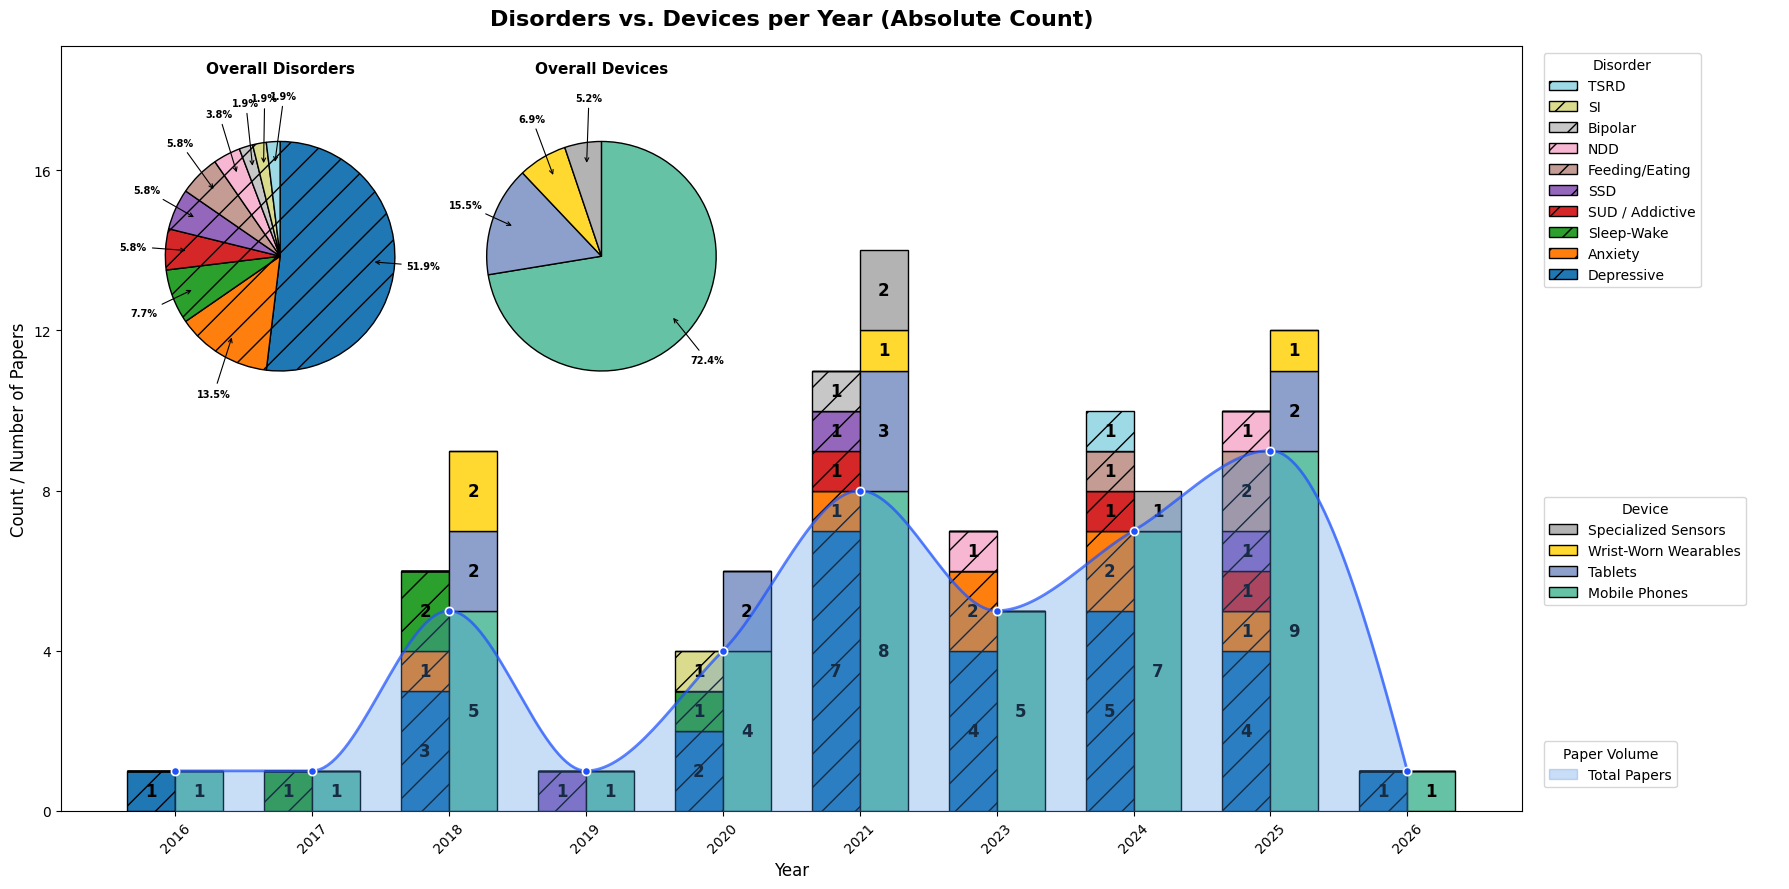

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator

# 1. Clean column names
df.columns = df.columns.str.strip()

# Convert Year column to float first, then to integer
df['Year'] = pd.to_numeric(df['Year'], errors='coerce').fillna(0).astype(int)

# --- 2. Process Disorders (MD) with Absolute Counting ---
df_md = df[df['Year'] > 0][['Year', 'MD']].dropna().copy()
df_md['Weight'] = 1
df_md['MD_split'] = df_md['MD'].astype(str).str.split(',')
df_md = df_md.explode('MD_split')
df_md['MD_split'] = df_md['MD_split'].str.strip()

# --- 3. Process Devices with Absolute Counting ---
df_dev = df[df['Year'] > 0][['Year', 'Device_category']].dropna().copy()
df_dev['Weight'] = 1
df_dev['Device_split'] = df_dev['Device_category'].astype(str).str.split(',')
df_dev = df_dev.explode('Device_split')
df_dev['Device_split'] = df_dev['Device_split'].str.strip()

# --- 4. Cross-tabulate by summing WEIGHTS ---
disorder_dist = (
    pd.crosstab(
        df_md['Year'],
        df_md['MD_split'],
        values=df_md['Weight'],
        aggfunc='sum',
    )
    .fillna(0)
    .astype(int)
)
device_dist = (
    pd.crosstab(
        df_dev['Year'],
        df_dev['Device_split'],
        values=df_dev['Weight'],
        aggfunc='sum',
    )
    .fillna(0)
    .astype(int)
)

# Align the datasets exactly to match the X-axis
all_years = sorted(list(set(disorder_dist.index).union(set(device_dist.index))))
disorder_dist = disorder_dist.reindex(all_years, fill_value=0)
device_dist = device_dist.reindex(all_years, fill_value=0)

# Sort columns by total volume
disorder_dist = disorder_dist[
    disorder_dist.sum().sort_values(ascending=False).index
]
device_dist = device_dist[device_dist.sum().sort_values(ascending=False).index]

# Calculate True Unique Papers Per Year
df_unique = df[df['Year'] > 0].copy()
papers_per_year = (
    df_unique.groupby('Year').size().reindex(all_years, fill_value=0)
)

# --- 5. Plotting (Dedicated 2-column layout: 4 parts plot, 1 part legends) ---
fig, (ax, ax_leg) = plt.subplots(
    1, 2, figsize=(18, 9), gridspec_kw={'width_ratios': [6, 1]}
)

# Hide axis lines, background, and ticks for the legend column
ax_leg.axis('off')

width = 0.35
x_pos = np.arange(len(all_years))

# Palettes
colors_dis = plt.cm.tab20(np.linspace(0, 1, len(disorder_dist.columns)))
colors_dev = plt.cm.Set2(np.linspace(0, 1, len(device_dist.columns)))
single_hatch = '/'

# Plot Disorders (Shifted Left)
bottom_dis = np.zeros(len(all_years))
for idx, col in enumerate(disorder_dist.columns):
    bars_dis = ax.bar(
        x_pos - width / 2,
        disorder_dist[col],
        width,
        label=col,
        bottom=bottom_dis,
        edgecolor='black',
        linewidth=1,
        color=colors_dis[idx],
        hatch=single_hatch,
    )
    labels_dis = [f'{int(val)}' if val > 0 else '' for val in disorder_dist[col]]
    ax.bar_label(
        bars_dis,
        labels=labels_dis,
        label_type='center',
        fontsize=12,
        fontweight='bold',
    )
    bottom_dis += disorder_dist[col]

# Plot Devices (Shifted Right)
bottom_dev = np.zeros(len(all_years))
for idx, col in enumerate(device_dist.columns):
    bars_dev = ax.bar(
        x_pos + width / 2,
        device_dist[col],
        width,
        label=col,
        bottom=bottom_dev,
        edgecolor='black',
        linewidth=1,
        color=colors_dev[idx],
    )
    labels_dev = [f'{int(val)}' if val > 0 else '' for val in device_dist[col]]
    ax.bar_label(
        bars_dev,
        labels=labels_dev,
        label_type='center',
        fontsize=12,
        fontweight='bold',
    )
    bottom_dev += device_dist[col]

# --- TRANSPARENT WAVE WITH ALPHA 0.3 ---
if len(x_pos) > 2:
    x_smooth = np.linspace(x_pos.min(), x_pos.max(), 300)
    pchip = PchipInterpolator(x_pos, papers_per_year)
    y_smooth = pchip(x_smooth)
else:
    x_smooth = x_pos
    y_smooth = papers_per_year

wave_fill = ax.fill_between(
    x_smooth, y_smooth, color='#4A90E2', alpha=0.3, zorder=4
)
ax.plot(x_smooth, y_smooth, color='#1F51FF', linewidth=2, alpha=0.7, zorder=5)

ax.scatter(
    x_pos,
    papers_per_year,
    color='#1F51FF',
    marker='o',
    s=35,
    edgecolor='white',
    linewidth=1.2,
    zorder=6,
)

# --- INSET PIE CHARTS ---
ax_pie_dis = ax.inset_axes([0, 0.5, 0.3, 0.45])
ax_pie_dev = ax.inset_axes([0.19, 0.5, 0.36, 0.45])

total_disorders = disorder_dist.sum()
total_devices = device_dist.sum()
dis_pie_hatches = [single_hatch for _ in range(len(disorder_dist.columns))]

wedges_dis, _ = ax_pie_dis.pie(
    total_disorders,
    colors=colors_dis,
    startangle=90,
    counterclock=False,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
    hatch=dis_pie_hatches,
)
ax_pie_dis.set_title(
    'Overall Disorders', fontsize=11, fontweight='bold', pad=8
)

wedges_dev, _ = ax_pie_dev.pie(
    total_devices,
    colors=colors_dev,
    startangle=90,
    counterclock=False,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
)
ax_pie_dev.set_title('Overall Devices', fontsize=11, fontweight='bold', pad=8)


def annotate_pie_with_arrows(wedges, totals, target_axis):
    sum_total = totals.sum()
    for idx, wedge in enumerate(wedges):
        percentage = 100.0 * totals.iloc[idx] / sum_total
        if percentage < 1.5:
            continue
        theta1, theta2 = wedge.theta1, wedge.theta2
        center_angle = np.deg2rad((theta1 + theta2) / 2.0)
        x_edge = np.cos(center_angle)
        y_edge = np.sin(center_angle)
        horiz_align = 'right' if x_edge > 0 else 'left'
        elongation = 1.4
        target_axis.annotate(
            f'{percentage:.1f}%',
            xy=(0.8 * x_edge, 0.8 * y_edge),
            xytext=(elongation  * x_edge, elongation  * y_edge),
            arrowprops=dict(arrowstyle='->', color='black', linewidth=0.8),
            ha=horiz_align,
            va='center',
            fontsize=7,
            fontweight='bold',
        )
    target_axis.set_xlim(-1.5, 1.5)
    target_axis.set_ylim(-1.5, 1.5)


annotate_pie_with_arrows(wedges_dis, total_disorders, ax_pie_dis)
annotate_pie_with_arrows(wedges_dev, total_devices, ax_pie_dev)

# --- 6. Formatting the Chart ---
ax.set_title(
    'Disorders vs. Devices per Year (Absolute Count)',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Count / Number of Papers', fontsize=12)

ax.set_xticks(x_pos)
ax.set_xticklabels(all_years, rotation=45)

ax.yaxis.set_major_locator(ticker.MultipleLocator(4))
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))

current_bottom, current_top = ax.get_ylim()
ax.set_ylim(0, current_top * 1.30)

# --- 7. Managing Legends (Anchored inside ax_leg) ---
handles, labels = ax.get_legend_handles_labels()

num_disorders = len(disorder_dist.columns)
num_devices = len(device_dist.columns)

dis_handles, dis_labels = handles[:num_disorders], labels[:num_disorders]
dev_handles, dev_labels = (
    handles[num_disorders : num_disorders + num_devices],
    labels[num_disorders : num_disorders + num_devices],
)

# 1st Legend: Disorder (Top)
leg1 = ax_leg.legend(
    dis_handles[::-1],
    dis_labels[::-1],
    title='Disorder',
    loc='upper left',
    bbox_to_anchor=(0.0, 1.0),
    frameon=True,
)
ax_leg.add_artist(leg1)

# 2nd Legend: Device (Middle)
leg2 = ax_leg.legend(
    dev_handles[::-1],
    dev_labels[::-1],
    title='Device',
    loc='upper left',
    bbox_to_anchor=(0.0, 0.42),
    frameon=True,
)
ax_leg.add_artist(leg2)

# 3rd Legend: Paper Volume (Bottom)
leg3 = ax_leg.legend(
    [wave_fill],
    ['Total Papers'],
    title='Paper Volume',
    loc='upper left',
    bbox_to_anchor=(0.0, 0.10),
    frameon=True,
)

# --- 8. Layout & Save ---
plt.tight_layout()
plt.savefig(
    'disorders_vs_devices_absolute_trends.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

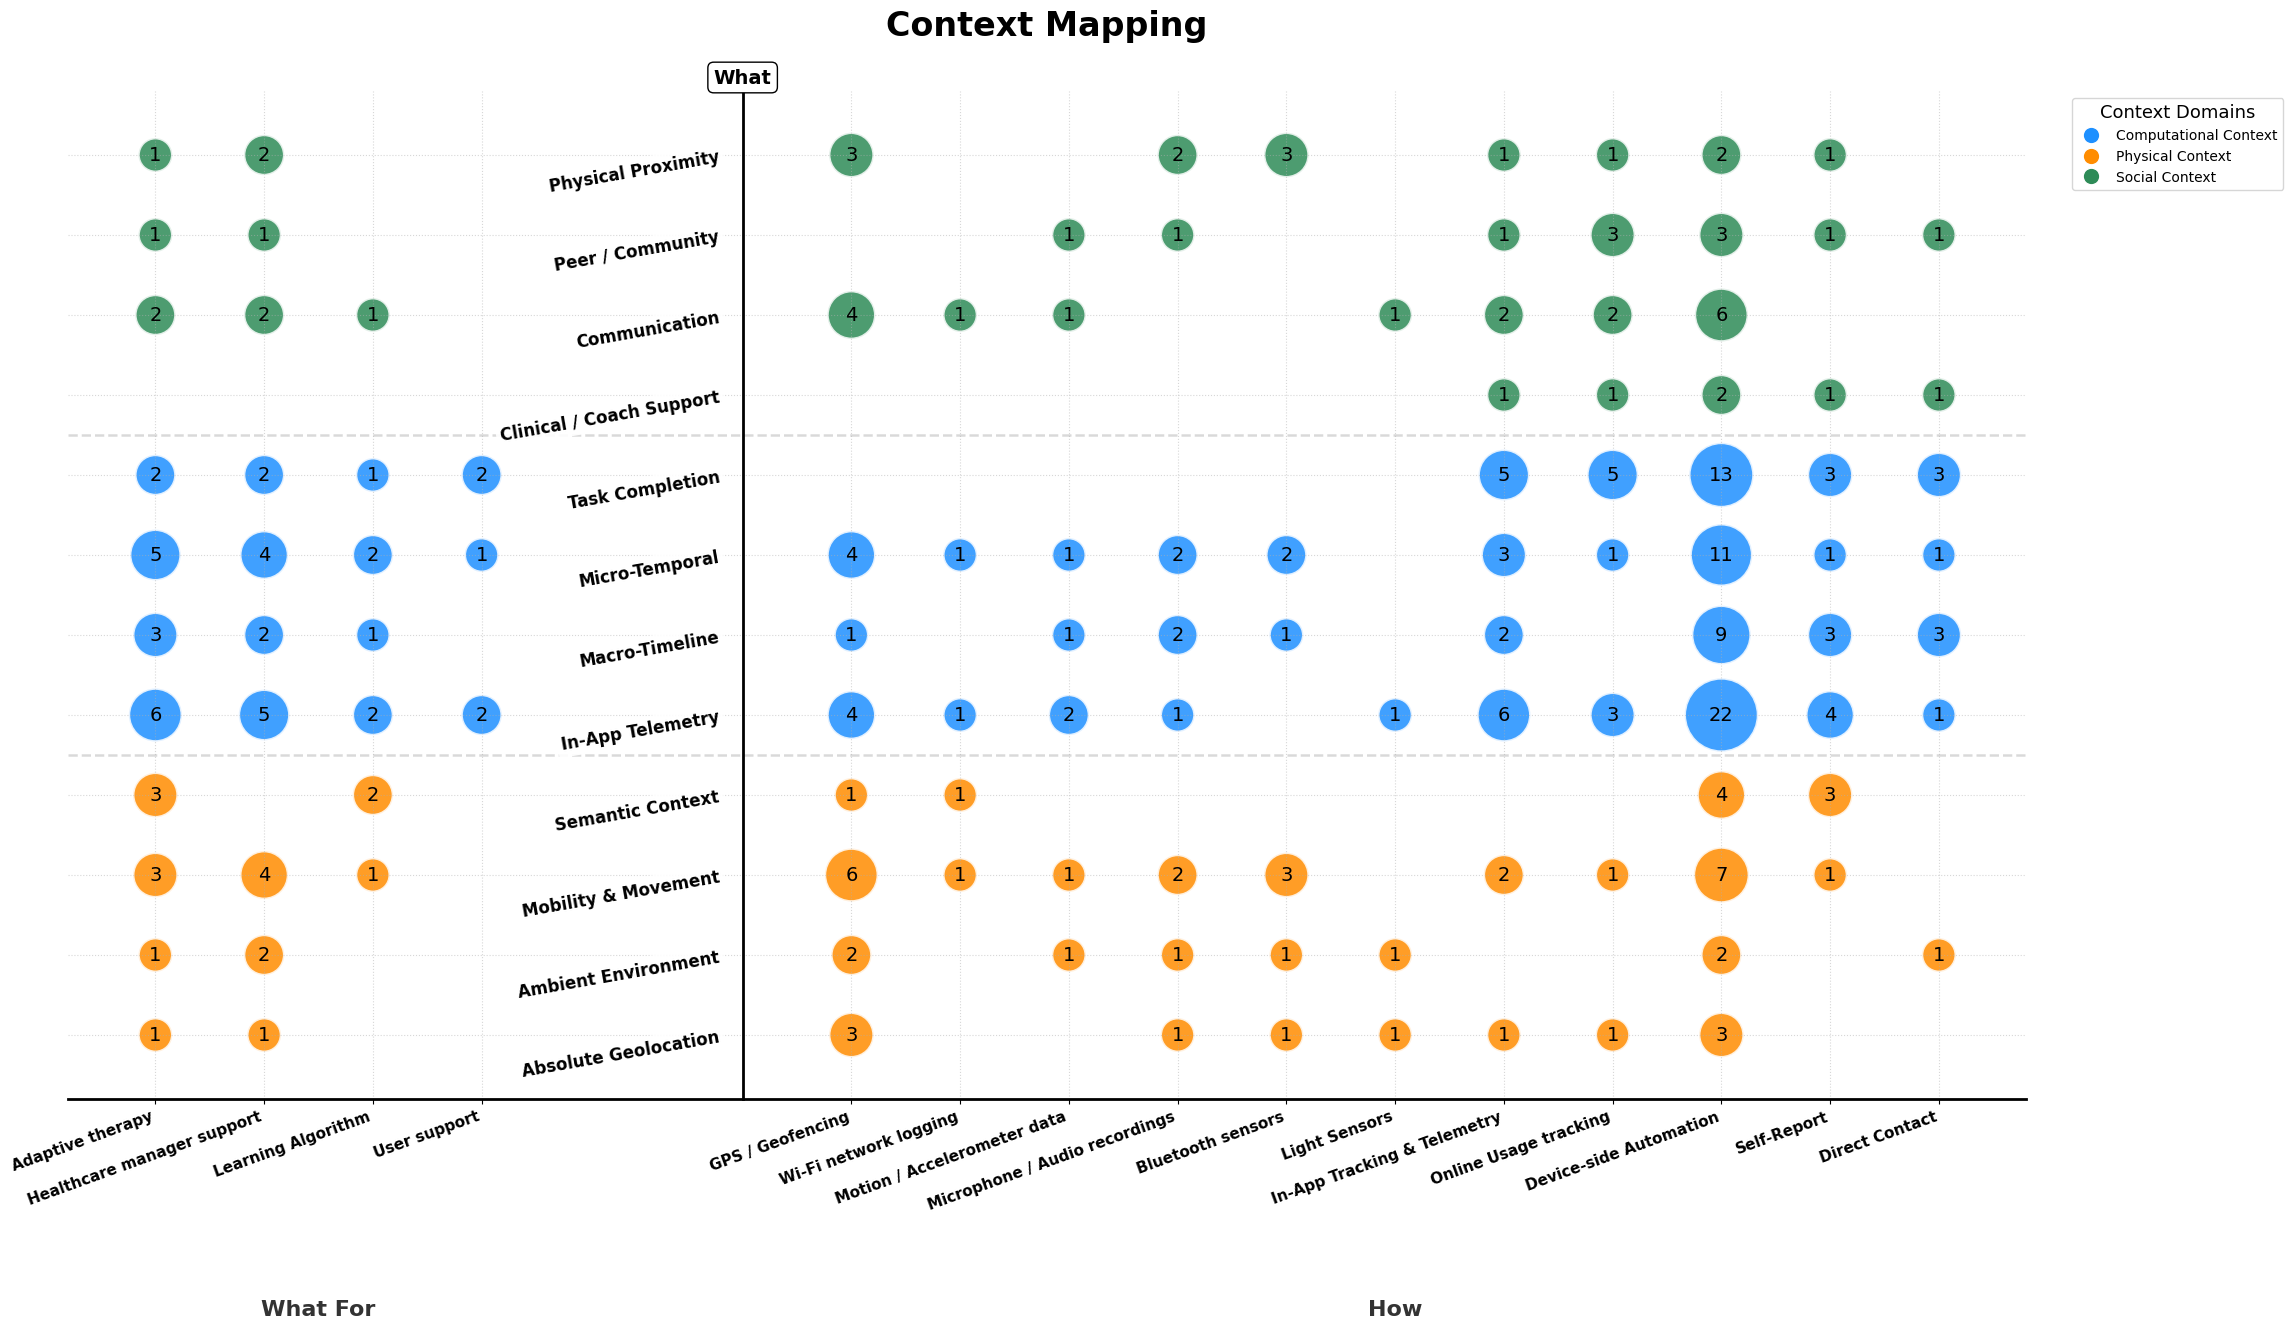

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# 1. Column Clean-up
df.columns = df.columns.str.strip()

# --- TRACKING LISTS CONFIGURATION ---
pc_w = ['WPC: MOB', 'WPC: SEM', 'WPC: ABS', 'WPC: AMB', 'WPC: VIR']
cc_w = ['WCC: APP', 'WCC: TSK', 'WCC: MAC', 'WCC: MIC']
sc_w = ['WSC: COM', 'WSC: PEER', 'WSC: CLIN', 'WSC: PROX']

# Global unified How columns
h_cols = ['H: GPS', 'H: WIF', 'H: MOT', 'H: MIC', 'H: BLS', 'H: LIS', 'H: VAR', 'H: APP', 'H: EOS', 'H: OUT', 'H: DSA', 'H: REP', 'H: DIR']
pc_h = cc_h = sc_h = h_cols

w_names = {
    'MOB': 'Mobility & Movement', 'SEM': 'Semantic Context',
    'ABS': 'Absolute Geolocation', 'AMB': 'Ambient Environment',
    'VIR': 'Virtual & Simulated',
    'APP': 'In-App Telemetry', 'TSK': 'Task Completion',
    'MAC': 'Macro-Timeline', 'MIC': 'Micro-Temporal',
    'COM': 'Communication', 'PEER': 'Peer / Community',
    'CLIN': 'Clinical / Coach Support', 'PROX': 'Physical Proximity'
}

h_names = {
    'GPS': 'GPS / Geofencing',
    'WIF': 'Wi-Fi network logging',
    'MOT': 'Motion / Accelerometer data',
    'MIC': 'Microphone / Audio recordings',
    'BLS': 'Bluetooth sensors',
    'LIS': 'Light Sensors',
    'VAR': 'VR / AR Headsets',
    'APP': 'In-App Tracking & Telemetry',
    'EOS': 'Environmental online services',
    'OUT': 'Online Usage tracking',
    'DSA': 'Device-side Automation',
    'REP': 'Self-Report',
    'DIR': 'Direct Contact'
}

groups = {
    'PC': {'w': pc_w, 'h': pc_h, 'color': '#FF8C00'},
    'CC': {'w': cc_w, 'h': cc_h, 'color': '#1E90FF'},
    'SC': {'w': sc_w, 'h': sc_h, 'color': '#2E8B57'}
}

# --- 2. RIGHT SIDE PROCESSING (WHAT vs HOW) ---
right_plot_data = []
for key, config in groups.items():
    for w_col in config['w']:
        for h_col in config['h']:
            if w_col in df.columns and h_col in df.columns:
                count = ((pd.to_numeric(df[w_col], errors='coerce').fillna(0) > 0) &
                         (pd.to_numeric(df[h_col], errors='coerce').fillna(0) > 0)).sum()
                if count > 0:
                    right_plot_data.append({
                        'W_label': w_col.split(': ')[1],
                        'H_label': h_col.split(': ')[1],
                        'Count': count,
                        'Color': config['color']
                    })
df_right_plot = pd.DataFrame(right_plot_data)

# --- 3. LEFT SIDE PROCESSING (WHAT vs WHAT FOR) ---

all_cats = set()
if 'Categorization' in df.columns:
    for val in df['Categorization'].fillna('').astype(str):
        for c in val.split(','):
            if c.strip():
                all_cats.add(c.strip())
raw_cat_order = sorted(list(all_cats))

left_plot_data = []
for key, config in groups.items():
    for w_col in config['w']:
        if w_col in df.columns and 'Categorization' in df.columns:
            w_label = w_col.split(': ')[1]
            w_numeric = pd.to_numeric(df[w_col], errors='coerce').fillna(0) > 0

            for cat in raw_cat_order:
                cat_mask = df['Categorization'].fillna('').astype(str).str.contains(cat, regex=False)
                count = (w_numeric & cat_mask).sum()
                if count > 0:
                    left_plot_data.append({
                        'W_label': w_label,
                        'Cat_label': cat,
                        'Count': count,
                        'Color': config['color']
                    })
df_left_plot = pd.DataFrame(left_plot_data)

# --- 4. AXIS ORDERING ---
active_w = set(df_right_plot['W_label'].unique()).union(set(df_left_plot['W_label'].unique() if not df_left_plot.empty else []))
active_h = df_right_plot['H_label'].unique() if not df_right_plot.empty else []
active_cat = df_left_plot['Cat_label'].unique() if not df_left_plot.empty else []

raw_h_order = [h.split(': ')[1] for h in (pc_h + cc_h + sc_h)]
unique_h_order = list(dict.fromkeys(raw_h_order))
h_order = [h for h in unique_h_order if h in active_h]

pc_w_clean = sorted(list(dict.fromkeys([w.split(': ')[1] for w in pc_w])))
cc_w_clean = sorted(list(dict.fromkeys([w.split(': ')[1] for w in cc_w])))
sc_w_clean = sorted(list(dict.fromkeys([w.split(': ')[1] for w in sc_w])))
unique_w_order = pc_w_clean + cc_w_clean + sc_w_clean

w_order = [w for w in unique_w_order if w in active_w]
cat_order = [c for c in raw_cat_order if c in active_cat]

# --- 5. T-SHAPE COORDINATE MAPPING WITH GAP PROTECTION ---
LEFT_WING_GAP = 1.4  # Creates a buffer corridor to prevent overlap with the rotated Y labels
y_map = {label: i for i, label in enumerate(w_order)}
x_map_left = {label: -(len(cat_order) - i) - LEFT_WING_GAP for i, label in enumerate(cat_order)}
x_map_right = {label: i + 1 for i, label in enumerate(h_order)}

# --- 6. UNIFIED PLOT GENERATION ---
fig, ax = plt.subplots(figsize=(27, 16))
plt.subplots_adjust(right=0.85, bottom=0.25)

global_max = max(
    df_right_plot['Count'].max() if not df_right_plot.empty else 1,
    df_left_plot['Count'].max() if not df_left_plot.empty else 1
)
scale_factor = 2800 / np.sqrt(global_max)

# Plot Left Wing (What For)
if not df_left_plot.empty:
    sizes_left = np.sqrt(df_left_plot['Count']) * scale_factor
    ax.scatter(
        df_left_plot['Cat_label'].map(x_map_left),
        df_left_plot['W_label'].map(y_map),
        s=sizes_left, c=df_left_plot['Color'], alpha=0.85, edgecolors='white', linewidth=2
    )
    for _, row in df_left_plot.iterrows():
        # Removed bold weight from bubble text
        ax.text(x_map_left[row['Cat_label']], y_map[row['W_label']], str(int(row['Count'])),
                ha='center', va='center', fontsize=14, color='black')

# Plot Right Wing (How)
if not df_right_plot.empty:
    sizes_right = np.sqrt(df_right_plot['Count']) * scale_factor
    ax.scatter(
        df_right_plot['H_label'].map(x_map_right),
        df_right_plot['W_label'].map(y_map),
        s=sizes_right, c=df_right_plot['Color'], alpha=0.85, edgecolors='white', linewidth=2
    )
    for _, row in df_right_plot.iterrows():
        # Removed bold weight from bubble text
        ax.text(x_map_right[row['H_label']], y_map[row['W_label']], str(int(row['Count'])),
                ha='center', va='center', fontsize=14, color='black')

# --- 7. T-SHAPE SPINE AND LABEL LAYOUT ---
ax.spines['left'].set_position(('data', 0))
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

x_positions = list(x_map_left.values()) + list(x_map_right.values())
x_labels_full = list(x_map_left.keys()) + [h_names.get(h, h) for h in x_map_right.keys()]

ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels_full, rotation=20, ha='right', fontsize=11, fontweight='bold')

# Full descriptive names rendered on Y-axis with bold weight removed
ax.set_yticks(range(len(w_order)))
ax.set_yticklabels([w_names.get(w, w) for w in w_order], rotation=10, ha='right', fontsize=12, fontweight='bold')
ax.tick_params(axis='y', which='both', left=False, right=False, pad=12)

# --- DYNAMIC DASHED LINES FOR CONTEXT SEPARATION ---
pc_labels_stripped = [w.split(': ')[1] for w in pc_w]
cc_labels_stripped = [w.split(': ')[1] for w in cc_w]
sc_labels_stripped = [w.split(': ')[1] for w in sc_w]

pc_indices = [i for i, w in enumerate(w_order) if w in pc_labels_stripped]
cc_indices = [i for i, w in enumerate(w_order) if w in cc_labels_stripped]
sc_indices = [i for i, w in enumerate(w_order) if w in sc_labels_stripped]

if pc_indices and cc_indices:
    ax.axhline(y=max(pc_indices) + 0.5, color='#444444', linestyle='--', linewidth=1.8, alpha=0.2, zorder=1)

if cc_indices and sc_indices:
    ax.axhline(y=max(cc_indices) + 0.5, color='#444444', linestyle='--', linewidth=1.8, alpha=0.2, zorder=1)

for label in ax.get_yticklabels():
    label.set_bbox(dict(facecolor='white', edgecolor='none', alpha=0.9, pad=3))

ax.set_xlim(-len(cat_order) - 0.8 - LEFT_WING_GAP, len(h_order) + 0.8)
ax.set_ylim(-0.8, len(w_order) - 0.2)
ax.grid(True, linestyle=':', alpha=0.5)

# --- 8. SUB-AXIS TITLE ANNOTATIONS ---
ax.text(-len(cat_order)/2 - 0.5 - LEFT_WING_GAP, -3.5, "What For", fontsize=16, fontweight='bold', ha='center', color='#333333')
ax.text(len(h_order)/2 + 0.5, -3.5, "How", fontsize=16, fontweight='bold', ha='center', color='#333333')
ax.text(0, len(w_order) - 0.1, "What", fontsize=14, fontweight='bold', ha='center', color='black',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))

ax.set_title("Context Mapping", fontsize=24, fontweight='bold', pad=40)

# --- 9. LEGEND AND SIMPLIFIED GLOSSARY ---
legend_el = [
    Line2D([0], [0], marker='o', color='w', label='Computational Context', markerfacecolor='#1E90FF', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Physical Context', markerfacecolor='#FF8C00', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Social Context', markerfacecolor='#2E8B57', markersize=12)
]
ax.legend(handles=legend_el, loc='upper left', bbox_to_anchor=(1.02, 1), title="Context Domains", title_fontsize=13)

# Save figure file as vector PDF format
plt.savefig('bubble_chart_final.pdf', bbox_inches='tight')

In [ ]:
!pip install -U "kaleido==0.2.1"
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.kaleido.scope.mathjax = None


# 1. Clean Column Names
df.columns = df.columns.str.strip()

# --- TRACKING LISTS CONFIGURATION (Aligned with df.columns) ---
pc_w = ['WPC: MOB', 'WPC: SEM', 'WPC: ABS', 'WPC: AMB', 'WPC: VIR']
cc_w = ['WCC: APP', 'WCC: TSK', 'WCC: MAC', 'WCC: MIC']
sc_w = ['WSC: COM', 'WSC: PEER', 'WSC: CLIN', 'WSC: PROX']

# Shared 'How' (H:) columns across all contexts
h_cols = [
    'H: GPS',
    'H: WIF',
    'H: MOT',
    'H: MIC',
    'H: BLS',
    'H: LIS',
    'H: VAR',
    'H: APP',
    'H: EOS',
    'H: OUT',
    'H: DSA',
    'H: REP',
    'H: DIR',
]

# Mapping dictionaries for clean labels
w_names = {
    'MOB': 'Mobility',
    'SEM': 'Semantic Location',
    'ABS': 'Absolute Location',
    'AMB': 'Ambient Environment',
    'VIR': 'Virtual Environment',
    'APP': 'In-App Telemetry',
    'TSK': 'Task Execution',
    'MAC': 'Macro-Time',
    'MIC': 'Micro-Time',
    'COM': 'Communication',
    'PEER': 'Peer Network',
    'CLIN': 'Clinical Staff',
    'PROX': 'Proximity',
}

h_names = {
    'GPS': 'GPS',
    'WIF': 'Wi-Fi',
    'MOT': 'Motion Sensing',
    'MIC': 'Microphone / Audio',
    'BLS': 'Bluetooth / BLE',
    'LIS': 'Light Sensor',
    'VAR': 'Varied Sensors',
    'APP': 'App Usage Logs',
    'EOS': 'Embedded OS Stats',
    'OUT': 'Outdoor Context',
    'DSA': 'Digital Assessment',
    'REP': 'Self-Report',
    'DIR': 'Direct Input',
}

groups = {
    'Physical Context': {'w': pc_w, 'h': h_cols},
    'Computing Context': {'w': cc_w, 'h': h_cols},
    'Social Context': {'w': sc_w, 'h': h_cols},
}

# 2. Co-occurrence Matrix Generation
plot_data = []
for context_name, config in groups.items():
  for w_col in config['w']:
    for h_col in config['h']:
      if w_col in df.columns and h_col in df.columns:
        # Sum non-zero / positive co-occurrences
        count = (
            (pd.to_numeric(df[w_col], errors='coerce').fillna(0) > 0)
            & (pd.to_numeric(df[h_col], errors='coerce').fillna(0) > 0)
        ).sum()

        if count > 0:
          w_abbr = w_col.split(': ')[1]
          h_abbr = h_col.split(': ')[1]

          plot_data.append({
              'Context': context_name,
              'What': w_names.get(w_abbr, w_abbr),
              'How': h_names.get(h_abbr, h_abbr),
              'Count': int(count),
          })

df_sunburst = pd.DataFrame(plot_data)
df_sunburst['Root'] = 'Context'

# --- 3. GENERATE SUNBURST PERSPECTIVES ---
color_map = {
    'Physical Context': '#FF8C00',  # Dark Orange
    'Computing Context': '#1E90FF',  # Dodger Blue
    'Social Context': '#2E8B57',  # Sea Green
    '(?)': '#d3d3d3',
}

# Perspective A: Context -> What -> How
fig_left = px.sunburst(
    df_sunburst,
    path=['Root', 'Context', 'What', 'How'],
    values='Count',
    color='Context',
    color_discrete_map=color_map,
)

# 2. Base Right Chart: Context -> How -> What
fig_right = px.sunburst(
    df_sunburst,
    path=['Root', 'Context', 'How', 'What'],
    values='Count',
    color='Context',
    color_discrete_map=color_map,
)

# Combine into side-by-side figure
trace_left = fig_left.data[0]
trace_right = fig_right.data[0]

trace_left.domain = {'x': [0.0, 0.48], 'y': [0.0, 1.0]}
trace_right.domain = {'x': [0.52, 1.0], 'y': [0.0, 1.0]}

fig = go.Figure(data=[trace_left, trace_right])

# Layout formatting
fig.update_layout(
    title=dict(
        text='Dual-Perspective Sunburst Mapping Landscape',
        font=dict(size=24, weight='bold'),
        x=0.5,
        y=0.98,
        xanchor='center',
    ),
    annotations=[
        dict(
            text='Perspective A: Context -> What -> How',
            font=dict(size=16, weight='bold'),
            showarrow=False,
            x=0.24,
            y=1.06,
            xref='paper',
            yref='paper',
            xanchor='center',
        ),
        dict(
            text='Perspective B: Context -> How -> What',
            font=dict(size=16, weight='bold'),
            showarrow=False,
            x=0.76,
            y=1.06,
            xref='paper',
            yref='paper',
            xanchor='center',
        ),
    ],
    width=1600,
    height=850,
    margin=dict(t=140, l=40, r=40, b=40),
)

# --- EXPORT TO VECTOR PDF ---
fig.write_image(
    'Dual_Sensing_Perspectives_Sunburst.pdf', engine='kaleido', width=1600, height=850
)
print('PDF generated successfully via Plotly + Kaleido!')

PDF generated successfully via Plotly + Kaleido!


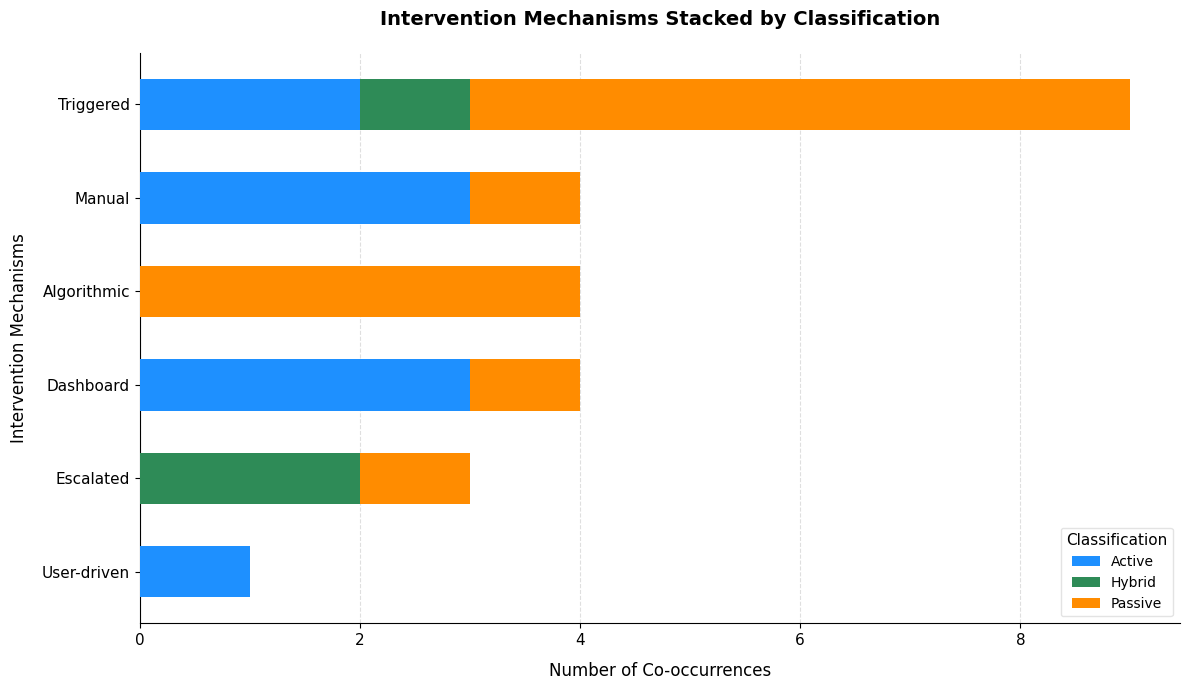

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Clean column names (Limpieza de columnas)
df.columns = df.columns.str.strip()

# --- 2. Crear un DataFrame limpio y procesar co-ocurrencias ---
df_clean = df[['Classification', 'Mechanism']].dropna().copy()


# Función para normalizar y separar valores por comas ',' y ampersands '&'
def split_and_clean(val):
  if pd.isna(val):
    return []
  # Reemplazamos '&' por ',' para tener un único delimitador común
  normalized = str(val).replace('&', ',')
  return [item.strip() for item in normalized.split(',') if item.strip()]


df_clean['Class_list'] = df_clean['Classification'].apply(split_and_clean)
df_clean['Mech_list'] = df_clean['Mechanism'].apply(split_and_clean)

# Explotamos primero las Clasificaciones para separarlas en filas individuales
df_exploded = df_clean.explode('Class_list')

# Unificamos 'Passive (User-driven)' en 'Passive' tal como se solicitó
df_exploded['Class_list'] = df_exploded['Class_list'].replace(
    {'Passive (User-driven)': 'Passive'}
)

# Explotamos los Mechanisms para obtener todas las combinaciones por fila (co-ocurrencias)
df_exploded = df_exploded.explode('Mech_list')

# Eliminar posibles valores vacíos por limpieza de strings
df_exploded = df_exploded[
    (df_exploded['Class_list'] != '') & (df_exploded['Mech_list'] != '')
]

# --- 3. Crear la tabla cruzada (Cross-tabulation) para apilar ---
stacked_data = pd.crosstab(df_exploded['Mech_list'], df_exploded['Class_list'])

# Ordenamos las barras por volumen total (las más frecuentes aparecerán arriba)
stacked_data['Total'] = stacked_data.sum(axis=1)
stacked_data = stacked_data.sort_values(by='Total', ascending=True)
stacked_data = stacked_data.drop(columns='Total')

# --- 4. Configurar el Lienzo y Graficar ---
fig, ax = plt.subplots(figsize=(12, 7))

# NUEVA PALETA: Colores personalizados
color_map = {
    'Active': '#1E90FF',  # Dodger Blue
    'Passive': '#FF8C00',  # Dark Orange
    'Hybrid': '#2E8B57',  # Sea Green
}

# Dibujar las barras apiladas acumulando el parámetro 'left'
left_counters = np.zeros(len(stacked_data))
for classification in stacked_data.columns:
  ax.barh(
      stacked_data.index,
      stacked_data[classification],
      left=left_counters,
      label=classification,
      height=0.55,
      color=color_map.get(classification, '#cccccc'),
      zorder=3,
  )
  left_counters += stacked_data[classification]

# --- 5. Formateo de Estética y Publicación ---
ax.set_title(
    'Intervention Mechanisms Stacked by Classification',
    fontsize=14,
    fontweight='bold',
    pad=20,
)
ax.set_xlabel('Number of Co-occurrences', fontsize=12, labelpad=10)
ax.set_ylabel('Intervention Mechanisms', fontsize=12, labelpad=10)

# Limpieza de bordes/espinas innecesarias
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=11)

# Añadir líneas de cuadrícula verticales sutiles por detrás
ax.grid(axis='x', linestyle='--', alpha=0.4, zorder=0)

# Configurar leyenda limpia
ax.legend(
    title='Classification',
    title_fontsize=11,
    loc='lower right',
    frameon=True,
    facecolor='white',
    edgecolor='#dddddd',
)

# Ajuste automático de márgenes
plt.tight_layout()

# --- 6. Guardar Gráfico en PDF Vectorial ---
plt.savefig(
    'mechanism_classification_stacked.pdf',
    format='pdf',
    bbox_inches='tight',
    dpi=300,
)
plt.show()

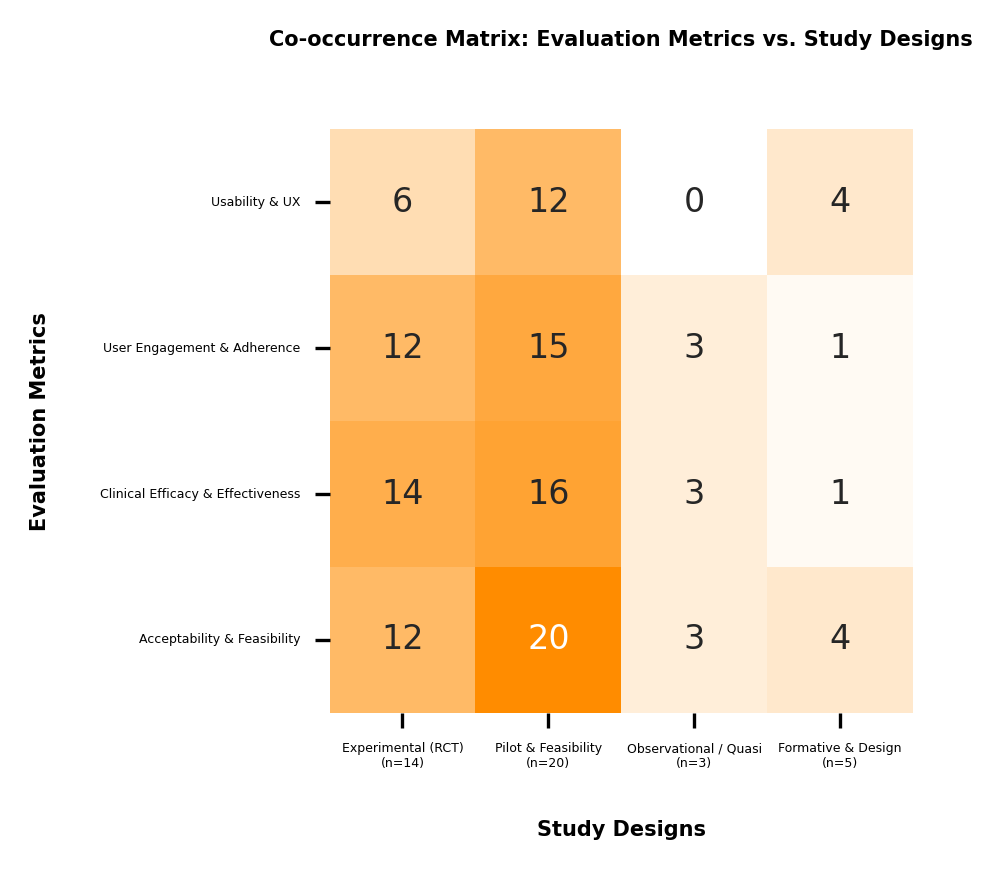

In [ ]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Clean and explode the 'Evaluation' column (split multi-label comma strings)
df_eval = df[['Category_ST', 'Evaluation']].copy()
df_eval['Evaluation_split'] = (
    df_eval['Evaluation'].astype(str).str.split(',')
)
df_eval = df_eval.explode('Evaluation_split')
df_eval['Evaluation_split'] = df_eval['Evaluation_split'].str.strip()

# 2. Compute co-occurrence matrix via crosstab
matrix = pd.crosstab(df_eval['Evaluation_split'], df_eval['Category_ST'])

# 3. Reindex rows and columns into exact custom orders
metric_order = [
    'Usability & UX',
    'User Engagement & Adherence',
    'Clinical Efficacy & Effectiveness',
    'Acceptability & Feasibility',
]
custom_col_order = [
    'Experimental (RCT)',
    'Pilot & Feasibility',
    'Observational / Quasi',
    'Formative & Design',
]

matrix = (
    matrix.reindex(index=metric_order, columns=custom_col_order)
    .fillna(0)
    .astype(int)
)

# --- Compute column totals from the dataframe directly to get the true n for each design ---
design_counts = df['Category_ST'].value_counts()
x_labels_with_counts = [
    f'{design}\n(n={design_counts.get(design, 0)})'
    for design in custom_col_order
]

# 4. Set up the figure layout (High resolution for academic prints)
fig, ax = plt.subplots(figsize=(6, 3), dpi=300)

# 5. Create the custom white-to-orange sequential colormap using '#FF8C00'
custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    'academic_oranges', ['#ffffff', '#FF8C00']
)

# 6. Generate the square heatmap
sns.heatmap(
    matrix,
    annot=True,  # Display raw counts inside the cells
    fmt='d',  # Clean integer formatting
    cmap=custom_cmap,
    square=True,  # Forces cells to remain strictly square
    cbar=False,  # REMOVES THE COLOR BAR
    annot_kws={'size': 8, 'fontname': 'sans-serif'},
    ax=ax,
)

# 7. Clean up typography and labels
ax.set_title(
    'Co-occurrence Matrix: Evaluation Metrics vs. Study Designs',
    size=5,
    weight='bold',
    pad=20,
    loc='center',
)
ax.set_xlabel('Study Designs', size=5, weight='bold', labelpad=12)
ax.set_ylabel('Evaluation Metrics', size=5, weight='bold', labelpad=12)

# Rotate labels cleanly to prevent overlapping and swap in the new labels with counts
ax.set_xticklabels(
    x_labels_with_counts, rotation=0, fontsize=3, fontname='sans-serif'
)
plt.yticks(rotation=0, fontsize=3, fontname='sans-serif')

plt.tight_layout()

# 8. Export as a vector PDF for publication
output_pdf_filename = 'ordered_axes_heatmap.pdf'
plt.savefig(output_pdf_filename, format='pdf', bbox_inches='tight')
plt.show()